## Week 4 Homework

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(url)

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [19]:
categorical = list(df.dtypes[df.dtypes == 'str'].index)
numerical = list(df.select_dtypes(include='number').columns)

categorical, numerical

(['lead_source', 'industry', 'employment_status', 'location'],
 ['annual_income',
  'number_of_courses_viewed',
  'interaction_count',
  'lead_score',
  'converted'])

## Data preparation
Check if the missing values are presented in the features.
1. If there are missing values:
    - For categorical features, replace them with 'NA'


    - For numerical features, replace with with 0.0

In [31]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0)

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [35]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [37]:
y_train = df_train['converted']
y_val = df_val['converted']

In [42]:
del df_train['converted']
del df_val['converted']

In [54]:
from sklearn.metrics import roc_auc_score

In [ ]:

feature_columns = [c for c in categorical + numerical if c != 'converted']

train_dict = df_train.rename(columns=str.lower)[feature_columns].to_dict(orient='records')
val_dict = df_val.rename(columns=str.lower)[feature_columns].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
val_dict = df_val.rename(columns=str.lower)[feature_columns].to_dict(orient='records')

dv = DictVectorizer(sparse=False) 
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

model = LogisticRegression(solver='liblinear', random_state=1)
model.fit(X_train,y_train) 

y_pred = model.predict_proba(X_val)[:,1]
print(round(roc_auc_score(y_val, y_pred), 3))


0.732


## Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that:

- For each numerical variable, use it as a score (aka prediction) and compute the AUC with the `y` variable as ground truth.
- Use the training dataset for that.

If your AUC is < 0.5, invert this variable by putting "-" in front (e.g. `-df_train['balance']`).

> **Note:** AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [ ]:
features = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

for col in features:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f'{col:28s} {auc:.3f}')


lead_score                   0.788
number_of_courses_viewed     0.723
interaction_count            0.765
annual_income                0.608


In [55]:
train_dict = df_train[feature_columns].to_dict(orient='records')
val_dict = df_val[feature_columns].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=1)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
print(round(roc_auc_score(y_val, y_pred), 3))

0.732


## Question 3: Precision and Recall

In [63]:
thresholds = np.linspace(0,1,100)

scores = []
for t in thresholds: 
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((float(t), int(tp), int(tn), int(fp), int(fn)))

import pandas as pd

columns = ['threshold', 'tp', 'tn', 'fp', 'fn']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['F1'] = 2 * (df_scores.precision * df_scores.recall) / (df_scores.precision + df_scores.recall)

df_scores[::10]

,threshold,tp,tn,fp,fn,precision,recall,fpr,tpr,F1
0,0.000000,586,0,414,0,0.586000,1.000000,1.000000,1.000000,0.738966
10,0.101010,586,0,414,0,0.586000,1.000000,1.000000,1.000000,0.738966
20,0.202020,586,0,414,0,0.586000,1.000000,1.000000,1.000000,0.738966
30,0.303030,586,13,401,0,0.593718,1.000000,0.968599,1.000000,0.745073
40,0.404040,573,56,358,13,0.615467,0.977816,0.864734,0.977816,0.755438
50,0.505051,522,126,288,64,0.644444,0.890785,0.695652,0.890785,0.747851
60,0.606061,456,230,184,130,0.712500,0.778157,0.444444,0.778157,0.743883
70,0.707071,298,342,72,288,0.805405,0.508532,0.173913,0.508532,0.623431
80,0.808081,126,393,21,460,0.857143,0.215017,0.050725,0.215017,0.343793
90,0.909091,11,413,1,575,0.916667,0.018771,0.002415,0.018771,0.036789


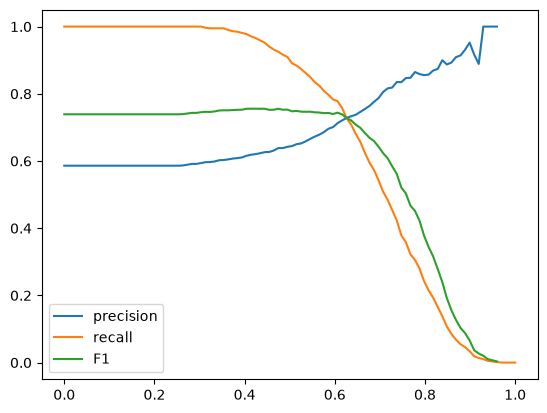

In [64]:
plt.plot(df_scores.threshold, df_scores.precision, label="precision")
plt.plot(df_scores.threshold, df_scores.recall, label="recall")
plt.plot(df_scores.threshold, df_scores.F1, label="F1")
plt.legend()

## K-Fold Cross Validation

In [70]:
def train(df, y, C=1.0):
    cat = df[categorical + numerical].to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    dv.fit(cat)

    X = dv.transform(cat)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)

    return dv, model

In [71]:
def predict(df,dv,model): 
   
   dicts = df[ categorical + numerical].to_dict(orient='records') 

   X = dv.transform(dicts)
   y_pred = model.predict_proba(X)[:,1]

   return y_pred

In [74]:
from sklearn.model_selection import KFold

nfolds = 5
kfold = KFold(n_splits=nfolds, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    aucs = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
        y_train = df_train["converted"].values
        y_val = df_val["converted"].values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
        
        auc = roc_auc_score(y_val, y_pred)
        aucs.append(auc)

    print('C=%s, auc = %0.3f ± %0.3f' % (C, np.mean(aucs), np.std(aucs)))



C=1e-06, auc = 0.618 ± 0.019
C=0.001, auc = 0.824 ± 0.010
C=1, auc = 0.923 ± 0.095


In [78]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

from tqdm.auto import tqdm

aucs = []

for train_idx, val_idx in tqdm(kfold.split(df_full_train)): 
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]
    
    y_train = df_train.converted.values
    y_val = df_val.converted.values
    dv, model = train(df_train, y_train)
    y_pred = predict(df_val,dv,model)

    auc = roc_auc_score(y_val, y_pred)
    aucs.append(auc)


0it [00:00, ?it/s]

In [80]:
print(f"Scores: {np.round(aucs, 3)}")
print(f"Mean: {np.mean(aucs):.3f}  Std: {np.std(aucs):.3f}")

Scores: [0.809 0.805 1.    1.    1.   ]
Mean: 0.923  Std: 0.095
